<a href="https://colab.research.google.com/github/logyfarg/ICU-XAI-FusionNet/blob/main/ICU_XAI_FusionNet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
from pathlib import Path
from zipfile import ZipFile

uploaded = files.upload()  # Select ICU-XAI-FusionNet.zip from your computer
zip_name = next(name for name in uploaded if name.endswith(".zip"))

project_dir = Path("/content/icu-xai-fusionnet")
project_dir.mkdir(exist_ok=True)

with ZipFile(zip_name) as archive:
    archive.extractall(project_dir)

%cd /content/icu-xai-fusionnet

Saving ICU-XAI-FusionNet.zip to ICU-XAI-FusionNet.zip
/content/icu-xai-fusionnet


In [ ]:
!pip -q install -r requirements.txt

In [ ]:
!rm -rf /content/physionet2019
!pip -q install awscli

!aws s3 sync --no-sign-request \
  s3://physionet-open/challenge-2019/1.0.0/training/ \
  /content/physionet2019/training/

Streaming output truncated to the last 5000 lines.
download: s3://physionet-open/challenge-2019/1.0.0/training/training_setB/p115001.psv to ../physionet2019/training/training_setB/p115001.psv
download: s3://physionet-open/challenge-2019/1.0.0/training/training_setB/p115002.psv to ../physionet2019/training/training_setB/p115002.psv
download: s3://physionet-open/challenge-2019/1.0.0/training/training_setB/p115004.psv to ../physionet2019/training/training_setB/p115004.psv
download: s3://physionet-open/challenge-2019/1.0.0/training/training_setB/p115005.psv to ../physionet2019/training/training_setB/p115005.psv
download: s3://physionet-open/challenge-2019/1.0.0/training/training_setB/p115003.psv to ../physionet2019/training/training_setB/p115003.psv
download: s3://physionet-open/challenge-2019/1.0.0/training/training_setB/p115007.psv to ../physionet2019/training/training_setB/p115007.psv
download: s3://physionet-open/challenge-2019/1.0.0/training/training_setB/p115009.psv to ../physionet20

In [ ]:
import glob

In [ ]:
paths = glob.glob("/content/physionet2019/**/*.psv", recursive=True)

In [ ]:
import glob
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

random.seed(42)

paths = glob.glob("/content/physionet2019/training/**/*.psv", recursive=True)
random.shuffle(paths)

static_columns = ["Age", "Gender", "Unit1", "Unit2", "HospAdmTime"]
excluded_columns = static_columns + ["SepsisLabel"]
rows = []

max_positive = 300
max_negative = 900
positive_count = 0
negative_count = 0

for path in paths:
    patient = pd.read_csv(path, sep="|")

    # Need 48 observation hours + 24 future hours for prediction target.
    if len(patient) < 72:
        continue

    # First 48 hours form the observation window.
    time_columns = [c for c in patient.columns if c not in excluded_columns]
    timeseries = patient.iloc[:48][time_columns].astype(float).values.tolist()

    # Sepsis occurs at any point in the following 24 hours.
    label = int(patient.iloc[48:72]["SepsisLabel"].max() > 0)

    if label == 1 and positive_count >= max_positive:
        continue
    if label == 0 and negative_count >= max_negative:
        continue

    static = {
        col: None if pd.isna(patient.iloc[0][col]) else float(patient.iloc[0][col])
        for col in static_columns
    }

    patient_id = f"{Path(path).parent.name}_{Path(path).stem}"

    rows.append({
        "subject_id": patient_id,
        "hadm_id": patient_id,
        "stay_id": patient_id,
        "index_time": "48h",
        "label": label,
        "timeseries": json.dumps(timeseries),
        "static": json.dumps(static),
        "text": ""
    })

    positive_count += label
    negative_count += 1 - label

    if positive_count >= max_positive and negative_count >= max_negative:
        break

dataset = pd.DataFrame(rows)

train, temporary = train_test_split(
    dataset, test_size=0.30, random_state=42, stratify=dataset["label"]
)
validation, test = train_test_split(
    temporary, test_size=0.50, random_state=42, stratify=temporary["label"]
)

output_dir = Path("data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

train.to_parquet(output_dir / "train.parquet", index=False)
validation.to_parquet(output_dir / "validation.parquet", index=False)
test.to_parquet(output_dir / "test.parquet", index=False)

print(dataset["label"].value_counts())
print(f"Created {len(train)} train, {len(validation)} validation, {len(test)} test patients.")

label
0    900
1    133
Name: count, dtype: int64
Created 723 train, 155 validation, 155 test patients.


In [ ]:
import yaml

with open("configs/default.yaml", encoding="utf-8") as f:
    config = yaml.safe_load(f)

config["feature_names"] = time_columns
config["data"]["train"] = "data/processed/train.parquet"
config["data"]["validation"] = "data/processed/validation.parquet"
config["data"]["test"] = "data/processed/test.parquet"

# Keeps the demonstration affordable on Colab GPU.
config["data"]["max_text_length"] = 32
config["training"]["batch_size"] = 4
config["training"]["epochs"] = 3
config["training"]["num_workers"] = 2
config["training"]["checkpoint_dir"] = "artifacts"

with open("configs/colab.yaml", "w", encoding="utf-8") as f:
    yaml.safe_dump(config, f, sort_keys=False)

In [ ]:
%cd /content/icu-xai-fusionnet

!ls data/processed
!ls configs

/content/icu-xai-fusionnet
test.parquet  train.parquet  validation.parquet
colab.yaml  default.yaml


In [ ]:
from pathlib import Path

path = Path("evaluation/metrics.py")
source = path.read_text()

source = source.replace(
    "for name, fn in {",
    "for name, plot_fn in {"
)

source = source.replace(
    "fig,ax=plt.subplots(); fn(ax);",
    "fig,ax=plt.subplots(); plot_fn(ax);"
)

path.write_text(source)
print("Fixed evaluation plotting bug.")

Fixed evaluation plotting bug.


In [ ]:
!python -m training.train --config configs/colab.yaml

/content/icu-xai-fusionnet/training/feature_selection.py:15: RuntimeWarning: Mean of empty slice
  summary=np.nanmean(np.asarray(timeseries,dtype=float),axis=1)
Loading weights: 100% 199/199 [00:00<00:00, 22340.58it/s]
[transformers] BertModel LOAD REPORT from: emilyalsentzer/Bio_ClinicalBERT
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; no

In [ ]:
!find artifacts -maxdepth 2 -type f

artifacts/test_metrics.json
artifacts/validation_metrics.json
artifacts/fusionnet.pt
artifacts/test_plots/confusion_matrix.png
artifacts/test_plots/precision_recall.png
artifacts/test_plots/calibration.png
artifacts/test_plots/roc.png
artifacts/structured_feature_ranking.json
artifacts/.gitkeep
artifacts/validation_plots/confusion_matrix.png
artifacts/validation_plots/precision_recall.png
artifacts/validation_plots/calibration.png
artifacts/validation_plots/roc.png


{'auroc': 0.4822222222222223, 'auprc': 0.19276458284561343, 'accuracy': 0.8709677419354839, 'precision': 0.0, 'recall': 0.0, 'sensitivity': 0.0, 'specificity': 1.0, 'f1': 0.0, 'mcc': 0.0, 'brier': 0.12547204592837743, 'ece': 0.11431628609857253, 'false_alarm_rate': 0.0, 'ppv': 0.0, 'npv': 0.8709677419354839, 'threshold': 0.5, 'confusion_matrix': [[135, 0], [20, 0]]}


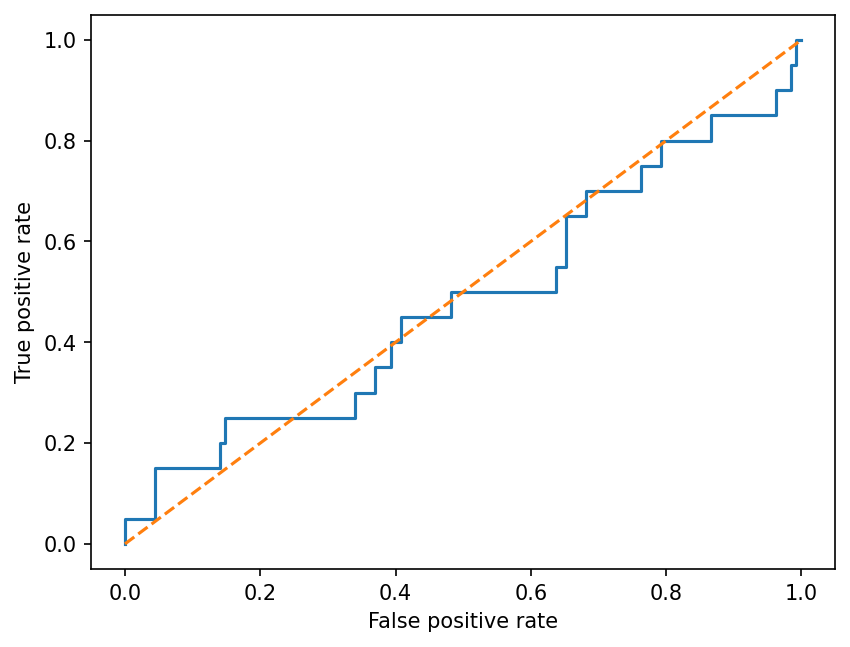

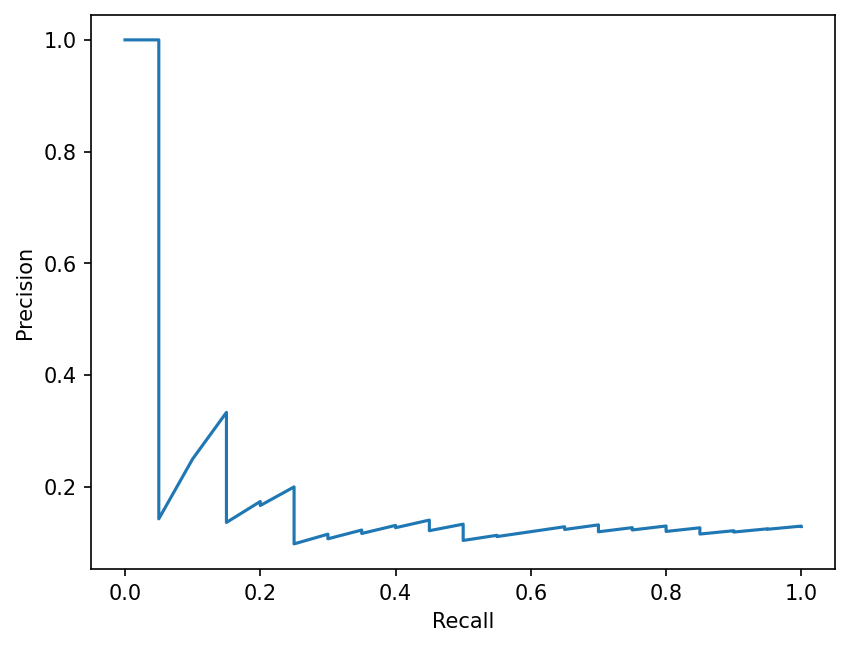

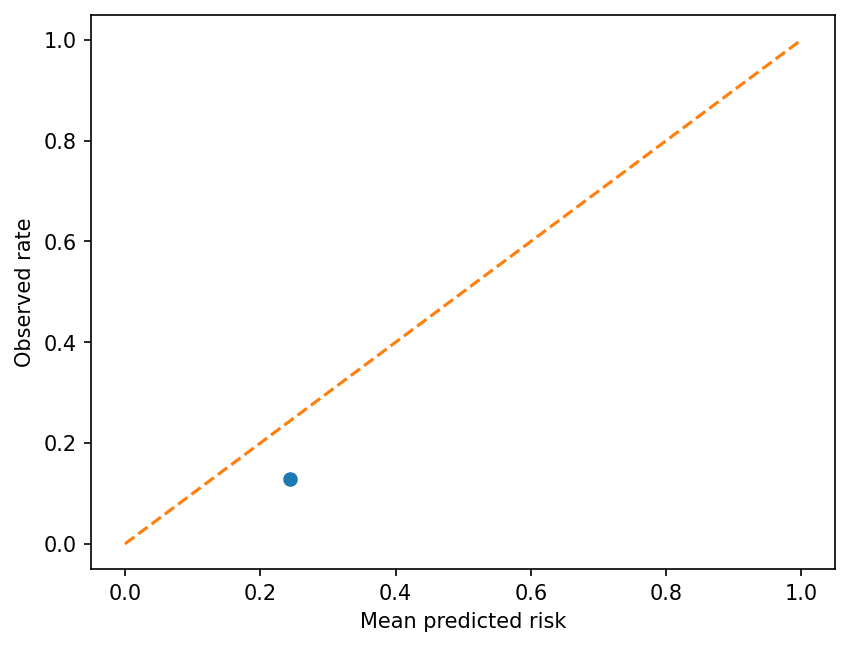

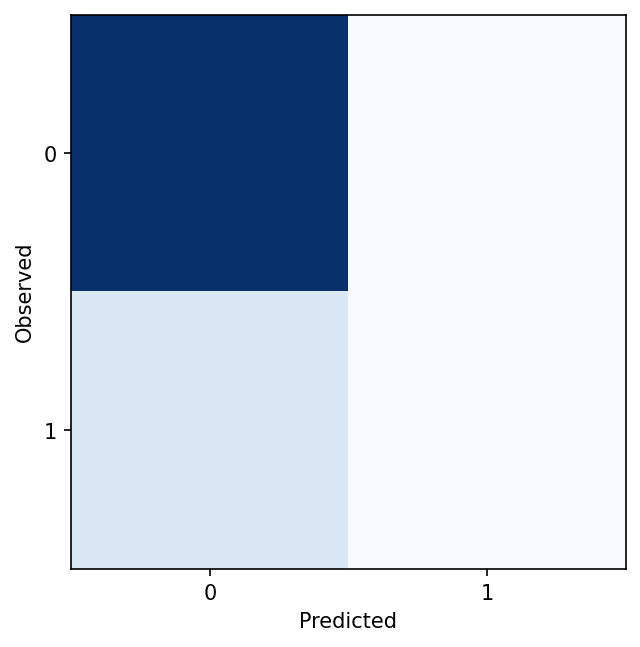

In [ ]:
from pathlib import Path
from PIL import Image
import json

artifacts = Path("artifacts")
print(json.loads((artifacts / "test_metrics.json").read_text()))

display(Image.open(artifacts / "test_plots" / "roc.png"))
display(Image.open(artifacts / "test_plots" / "precision_recall.png"))
display(Image.open(artifacts / "test_plots" / "calibration.png"))
display(Image.open(artifacts / "test_plots" / "confusion_matrix.png"))